# Comparación de los 4 modelos — RT-IoT2022

Este notebook **no entrena nada**: solo lee los CSV que guardan los notebooks de cada modelo en `resultados/` y genera las figuras y tablas para el paper.

Orden de ejecución previo: `preparacion_datos.ipynb` → `knn.ipynb`, `redes_neuronales.ipynb` y `preparacion_datos_Rashel.ipynb` (árbol y bosque) → este notebook.

1. Justificación de hiperparámetros (una figura y una tabla por modelo).
2. Matrices de confusión de árbol y bosque (KNN y red generan la suya en su notebook, con el mismo estilo).
3. Comparación en prueba: tabla comparativa y recall por clase.
4. Distribución de clases.

In [1]:
import ast
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

RES = Path("resultados")
DIR_COMP = RES / "comparacion"
DIR_COMP.mkdir(parents=True, exist_ok=True)

### Estilo de las figuras del paper (igual que fig1 y fig2 de cada modelo)
plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'font.size': 11,
    'axes.titlesize': 12,
    'axes.labelsize': 11,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'figure.dpi': 150,
    'savefig.dpi': 300,
    'savefig.facecolor': 'white',
})
BLACK, GRAY, LIGHT = '#000000', '#444444', '#d9d9d9'

SSH, FIN = "Metasploit_Brute_Force_SSH", "NMAP_FIN_SCAN"

### Nombre en las figuras -> carpeta en resultados/ (orden de la tabla comparativa)
MODELOS = {
    "Árbol de decisión": "arbol_decision",
    "Bosque aleatorio": "bosque_aleatorio",
    "KNN": "knn",
    "Red neuronal": "red_neuronal",
}

### Funciones de las figuras

- **Hiperparámetros**: eje X de menos a más complejo, dos curvas (entrenamiento y validación), la configuración elegida marcada con un punto y una línea vertical. Las zonas se marcan con una regla fija:
  - *Subajuste*: a la izquierda de la elegida, la validación queda más de 0,02 por debajo de la elegida y el entrenamiento más de 0,02 por debajo de su máximo (ambas curvas bajas).
  - *Sobreajuste*: a la derecha de la elegida, el entrenamiento se mantiene alto, la validación queda por debajo de la elegida y la brecha entrenamiento − validación es positiva y mayor que en la elegida.
  - Si una zona no aparece en el rango probado, se indica en la figura.
- **Matriz de confusión**: mismo estilo que la de KNN y la red (Greys, escala logarítmica, celdas en 0 en blanco).

In [2]:
def tramos(mascara):
    """Tramos contiguos (inicio, fin) donde la máscara es verdadera."""
    idx = np.flatnonzero(mascara)
    if len(idx) == 0:
        return []
    cortes = np.flatnonzero(np.diff(idx) > 1)
    return list(zip(np.r_[idx[0], idx[cortes + 1]], np.r_[idx[cortes], idx[-1]]))


def figura_hiperparametros(etiquetas_x, f1_ent, f1_val, i_eleg, titulo, detalle, xlabel, ruta, tol=0.02):
    ent, val = np.asarray(f1_ent, dtype=float), np.asarray(f1_val, dtype=float)
    x = np.arange(len(val))
    brecha = ent - val

    ### Zonas de subajuste y sobreajuste (regla descrita arriba)
    es_sub = (x < i_eleg) & (val < val[i_eleg] - tol) & (ent < ent.max() - tol)
    es_sobre = ((x > i_eleg) & (val < val[i_eleg]) & (ent >= ent[i_eleg] - 0.005)
                & (brecha > max(brecha[i_eleg], 0) + 0.005))

    fig, ax = plt.subplots(figsize=(9.0, 5.0))
    ymin = max(0.0, np.floor((min(ent.min(), val.min()) - 0.03) * 20) / 20)
    ax.set_ylim(ymin, 1.04)

    sin_zona = []
    for mascara, nombre, estilo in [(es_sub, "Subajuste", dict(facecolor="#e9e9e9")),
                                    (es_sobre, "Sobreajuste", dict(facecolor="white", hatch="///", edgecolor="#bdbdbd"))]:
        zonas = tramos(mascara)
        if not zonas:
            sin_zona.append(nombre.lower())
        for ini, fin in zonas:
            ax.axvspan(ini - 0.5, fin + 0.5, zorder=0, linewidth=0, **estilo)
            ax.text((ini + fin) / 2, 0.985, nombre, transform=ax.get_xaxis_transform(),
                    ha="center", va="top", fontsize=10, color=GRAY, fontweight="bold",
                    bbox=dict(facecolor="white", edgecolor="none", pad=1.5))

    ax.plot(x, ent, color=GRAY, linestyle="--", marker="s", markersize=5, linewidth=1.4, label="Entrenamiento")
    ax.plot(x, val, color=BLACK, linestyle="-", marker="o", markersize=5, linewidth=1.6, label="Validación")

    ### Configuración elegida
    ax.axvline(i_eleg, color=BLACK, linestyle=":", linewidth=1.2, zorder=1)
    ax.plot(i_eleg, val[i_eleg], marker="o", markersize=12, markerfacecolor="white",
            markeredgecolor=BLACK, markeredgewidth=2, zorder=5, linestyle="none", label="Configuración elegida")
    dx = -0.35 * len(x) if i_eleg > len(x) / 2 else 0.12 * len(x)
    ax.annotate(f"Elegida: {etiquetas_x[i_eleg].replace(chr(10), ' ')}\nF1 validación = {val[i_eleg]:.3f}",
                xy=(i_eleg, val[i_eleg]),
                xytext=(min(max(i_eleg + dx, 0), len(x) - 1), ymin + 0.35 * (val[i_eleg] - ymin)),
                fontsize=10, ha="left", va="center",
                arrowprops=dict(arrowstyle="->", color=BLACK, linewidth=1.0),
                bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor=GRAY, linewidth=0.8))

    if sin_zona:
        ax.text(0.99, 0.02, "No se observa " + " ni ".join(sin_zona) + " en el rango probado",
                transform=ax.transAxes, ha="right", va="bottom", fontsize=9, color=GRAY, style="italic")

    ax.set_xticks(x, etiquetas_x)
    ax.set_xlim(-0.5, len(x) - 0.5)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("macro-F1")
    ax.set_title(titulo, pad=22)
    ax.text(0.5, 1.015, detalle, transform=ax.transAxes, ha="center", va="bottom", fontsize=9, color=GRAY)
    ax.grid(axis="y", color="#e3e3e3", linewidth=0.6)
    ax.legend(loc="lower left", bbox_to_anchor=(0.0, 0.08), frameon=True, framealpha=0.95, fontsize=9)
    plt.tight_layout()
    plt.savefig(ruta, dpi=300)
    plt.show()
    print("Guardada:", ruta)


def matriz_confusion(cm, etiquetas, titulo, ruta):
    """Mismo estilo que la matriz de KNN y de la red (estilo por defecto de matplotlib)."""
    cm = np.asarray(cm)
    with plt.style.context("default"):
        cm_log = np.ma.masked_equal(cm, 0)
        cmap = plt.get_cmap("Greys").copy()
        cmap.set_bad("white")

        fig, ax = plt.subplots(figsize=(9, 8))
        im = ax.imshow(cm_log, cmap=cmap, norm=LogNorm(vmin=1, vmax=cm.max()))
        for i in range(cm.shape[0]):
            for j in range(cm.shape[1]):
                if cm[i, j] > 0:
                    ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8,
                            color="white" if im.norm(cm[i, j]) > 0.5 else "black")
        ax.set_xticks(range(len(etiquetas)), etiquetas, rotation=90)
        ax.set_yticks(range(len(etiquetas)), etiquetas)
        ax.set_xlabel("Clase predicha")
        ax.set_ylabel("Clase real")
        ax.set_title(titulo)
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="Número de registros (escala log)")
        plt.tight_layout()
        plt.savefig(ruta, dpi=300)
        plt.show()
    print("Guardada:", ruta)


def texto_profundidad(p):
    return "sin límite" if pd.isna(p) else str(int(p))

## 1. Justificación de hiperparámetros

### Árbol de decisión: profundidad máxima

La búsqueda (`busqueda_hiperparametros.csv`) se guardó ordenada por macro-F1 de validación: su primera fila es la configuración elegida. La curva (`arbol_curva_max_depth.csv`) varía solo `max_depth` con el resto de hiperparámetros fijos en los elegidos; en las profundidades que ya estaban en la grilla debe dar el mismo F1.

Guardada: resultados/arbol_decision/arbol_tabla_configuraciones.csv (96 de la grilla + 12 de la curva)


,configuracion,origen,max_depth,min_samples_split,min_samples_leaf,class_weight,criterion,F1_entrenamiento,F1_validacion,brecha_F1,elegida
29,30,grilla,10,10,1,ninguno,entropy,0.9607,0.9625,-0.0018,sí


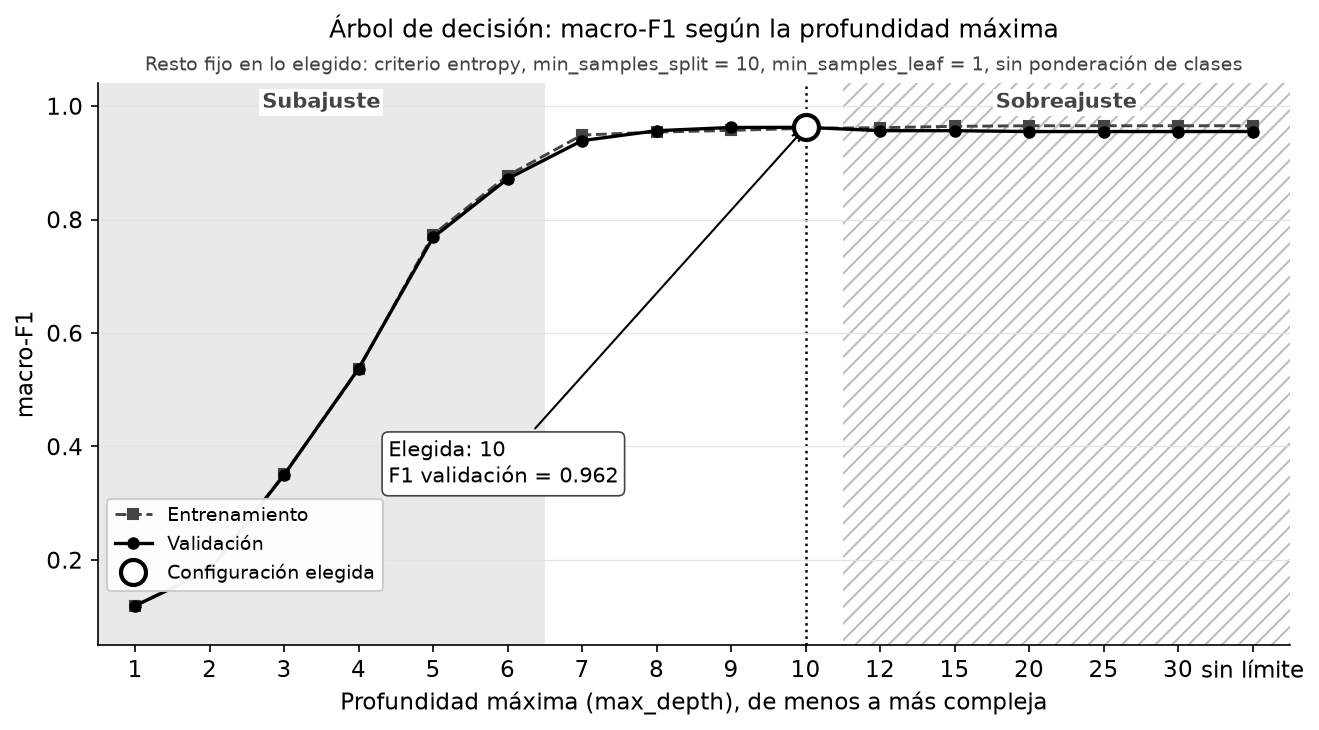

Guardada: resultados/arbol_decision/arbol_optimizacion_hiperparametros.png


In [3]:
def tabla_configuraciones_arbol(busq, curva, columnas, ruta):
    """Grilla completa + puntos extra de la curva de max_depth, con F1 de entrenamiento, validación y brecha."""
    clave = [c for c in columnas if c not in ("F1_T", "F1_V")]
    grilla = busq.sort_index().assign(configuracion=lambda t: t.index + 1, origen="grilla")
    curva = curva.astype({"peso_clases": grilla["peso_clases"].dtype})   # en el árbol la columna viene vacía y se lee como número

    ### Puntos de la curva que no estaban en la grilla
    en_grilla = curva.merge(grilla[clave + ["F1_V"]], on=clave, how="left", suffixes=("", "_grilla"), indicator=True)
    repetidos = en_grilla[en_grilla["_merge"] == "both"]
    assert np.allclose(repetidos["F1_V"], repetidos["F1_V_grilla"]), "La curva no reproduce la grilla"
    extra = curva[(en_grilla["_merge"] == "left_only").values].copy()
    extra["configuracion"] = range(len(grilla) + 1, len(grilla) + len(extra) + 1)
    extra["origen"] = "curva max_depth"

    tabla = pd.concat([grilla, extra], ignore_index=True)
    tabla["elegida"] = np.where(tabla["configuracion"] == busq.index[0] + 1, "sí", "")
    tabla["profundidad"] = tabla["profundidad"].map(texto_profundidad)
    tabla["peso_clases"] = tabla["peso_clases"].fillna("ninguno")
    tabla["brecha_F1"] = tabla["F1_T"] - tabla["F1_V"]
    tabla = tabla.rename(columns={
        "n_arboles": "n_estimators", "profundidad": "max_depth", "obs_dividir": "min_samples_split",
        "obs_hoja": "min_samples_leaf", "n_atributos": "max_features", "peso_clases": "class_weight",
        "criterio": "criterion", "F1_T": "F1_entrenamiento", "F1_V": "F1_validacion"})
    orden = ["configuracion", "origen"] + [c for c in tabla.columns if c not in
             ("configuracion", "origen", "F1_entrenamiento", "F1_validacion", "brecha_F1", "elegida")]
    tabla = tabla[orden + ["F1_entrenamiento", "F1_validacion", "brecha_F1", "elegida"]].round(4)
    tabla.to_csv(ruta, index=False)
    print(f"Guardada: {ruta} ({len(grilla)} de la grilla + {len(extra)} de la curva)")
    return tabla


busq_dt = pd.read_csv(RES / "arbol_decision/busqueda_hiperparametros.csv", index_col=0)
curva_dt = pd.read_csv(RES / "arbol_decision/arbol_curva_max_depth.csv")
eleg_dt = busq_dt.iloc[0]

tabla_dt = tabla_configuraciones_arbol(busq_dt, curva_dt, list(curva_dt.columns),
                                       RES / "arbol_decision/arbol_tabla_configuraciones.csv")
display(tabla_dt[tabla_dt["elegida"] == "sí"])

i_eleg = [k for k, p in enumerate(curva_dt["profundidad"])
          if texto_profundidad(p) == texto_profundidad(eleg_dt["profundidad"])][0]
figura_hiperparametros(
    [texto_profundidad(p) for p in curva_dt["profundidad"]], curva_dt["F1_T"], curva_dt["F1_V"], i_eleg,
    titulo="Árbol de decisión: macro-F1 según la profundidad máxima",
    detalle=(f"Resto fijo en lo elegido: criterio {eleg_dt['criterio']}, min_samples_split = {int(eleg_dt['obs_dividir'])}, "
             f"min_samples_leaf = {int(eleg_dt['obs_hoja'])}, sin ponderación de clases"),
    xlabel="Profundidad máxima (max_depth), de menos a más compleja",
    ruta=RES / "arbol_decision/arbol_optimizacion_hiperparametros.png")

### Bosque aleatorio: profundidad máxima

La grilla original solo probó profundidad 10 y sin límite; la curva (`bosque_curva_max_depth.csv`) completa el recorrido con el resto de hiperparámetros fijos en los elegidos. El modelo final no cambia.

Guardada: resultados/bosque_aleatorio/bosque_tabla_configuraciones.csv (16 de la grilla + 10 de la curva)


,configuracion,origen,n_estimators,max_depth,min_samples_split,min_samples_leaf,max_features,class_weight,criterion,F1_entrenamiento,F1_validacion,brecha_F1,elegida
10,11,grilla,100,sin límite,2,1,7,balanced_subsample,gini,0.9981,0.9731,0.0251,sí


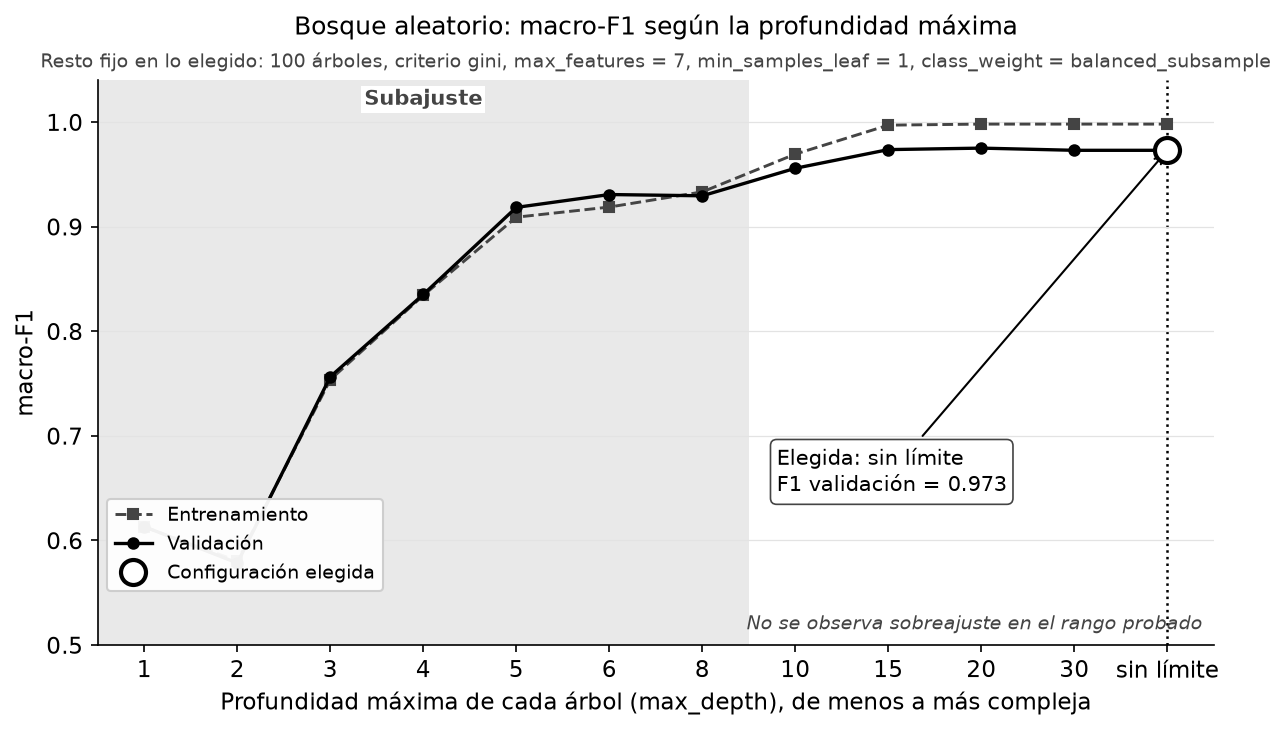

Guardada: resultados/bosque_aleatorio/bosque_optimizacion_hiperparametros.png


In [4]:
busq_rf = pd.read_csv(RES / "bosque_aleatorio/busqueda_hiperparametros.csv", index_col=0)
curva_rf = pd.read_csv(RES / "bosque_aleatorio/bosque_curva_max_depth.csv")
eleg_rf = busq_rf.iloc[0]

tabla_rf = tabla_configuraciones_arbol(busq_rf, curva_rf, list(curva_rf.columns),
                                       RES / "bosque_aleatorio/bosque_tabla_configuraciones.csv")
display(tabla_rf[tabla_rf["elegida"] == "sí"])

i_eleg = [k for k, p in enumerate(curva_rf["profundidad"])
          if texto_profundidad(p) == texto_profundidad(eleg_rf["profundidad"])][0]
figura_hiperparametros(
    [texto_profundidad(p) for p in curva_rf["profundidad"]], curva_rf["F1_T"], curva_rf["F1_V"], i_eleg,
    titulo="Bosque aleatorio: macro-F1 según la profundidad máxima",
    detalle=(f"Resto fijo en lo elegido: {int(eleg_rf['n_arboles'])} árboles, criterio {eleg_rf['criterio']}, "
             f"max_features = {int(eleg_rf['n_atributos'])}, min_samples_leaf = {int(eleg_rf['obs_hoja'])}, "
             f"class_weight = {eleg_rf['peso_clases']}"),
    xlabel="Profundidad máxima de cada árbol (max_depth), de menos a más compleja",
    ruta=RES / "bosque_aleatorio/bosque_optimizacion_hiperparametros.png")

### KNN: número de vecinos

Se usa el mismo criterio de elección que `knn.ipynb` (mayor macro-F1 de validación; a igualdad, menor k). Un k grande promedia muchos vecinos (modelo más simple); un k pequeño sigue cada punto (más complejo), así que el eje va de k grande a k pequeño. Con pesos por distancia, cada punto de entrenamiento es su propio vecino más cercano, por eso el F1 de entrenamiento queda casi en 1 para todo k.

Guardada: resultados/knn/knn_tabla_configuraciones.csv


,configuracion,n_neighbors,weights,distancia,p,F1_entrenamiento,F1_validacion,brecha_F1,elegida
31,32,3,distance,euclidiana,2,0.9981,0.9582,0.0399,sí


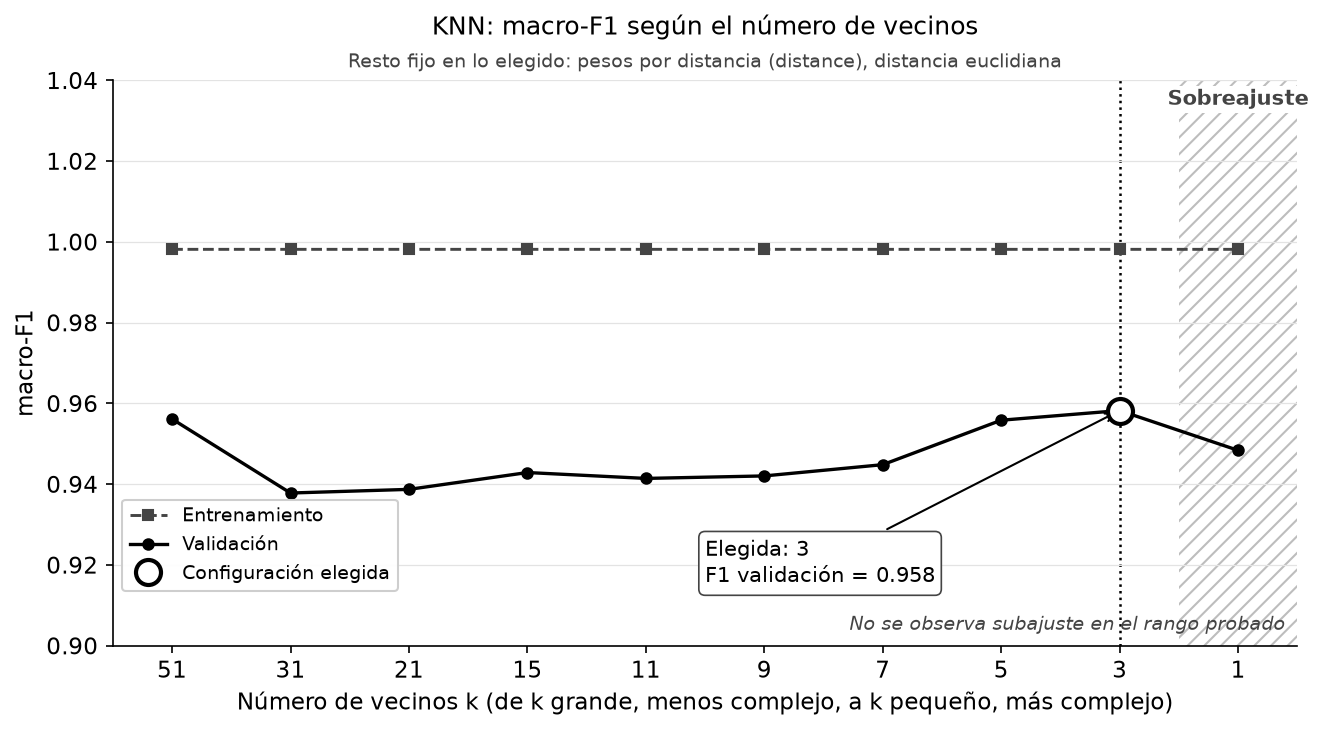

Guardada: resultados/knn/knn_optimizacion_hiperparametros.png


In [5]:
busq_knn = pd.read_csv(RES / "knn/busqueda_hiperparametros.csv")
eleg_knn = busq_knn.sort_values(["f1_macro_val", "k"], ascending=[False, True]).iloc[0]

### Tabla con las 40 configuraciones probadas
tabla_knn = (busq_knn.assign(configuracion=range(1, len(busq_knn) + 1),
                             brecha_F1=busq_knn["f1_train"] - busq_knn["f1_macro_val"],
                             elegida=np.where(busq_knn.index == eleg_knn.name, "sí", ""))
             .rename(columns={"k": "n_neighbors", "pesos": "weights", "f1_train": "F1_entrenamiento",
                              "f1_macro_val": "F1_validacion"})
             [["configuracion", "n_neighbors", "weights", "distancia", "p",
               "F1_entrenamiento", "F1_validacion", "brecha_F1", "elegida"]].round(4))
tabla_knn.to_csv(RES / "knn/knn_tabla_configuraciones.csv", index=False)
print("Guardada:", RES / "knn/knn_tabla_configuraciones.csv")
display(tabla_knn[tabla_knn["elegida"] == "sí"])

curva_knn = (busq_knn[(busq_knn["pesos"] == eleg_knn["pesos"]) & (busq_knn["p"] == eleg_knn["p"])]
             .sort_values("k", ascending=False).reset_index(drop=True))
i_eleg = int(np.flatnonzero(curva_knn["k"] == eleg_knn["k"])[0])
figura_hiperparametros(
    [str(k) for k in curva_knn["k"]], curva_knn["f1_train"], curva_knn["f1_macro_val"], i_eleg,
    titulo="KNN: macro-F1 según el número de vecinos",
    detalle=f"Resto fijo en lo elegido: pesos por distancia ({eleg_knn['pesos']}), distancia {eleg_knn['distancia']}",
    xlabel="Número de vecinos k (de k grande, menos complejo, a k pequeño, más complejo)",
    ruta=RES / "knn/knn_optimizacion_hiperparametros.png")

### Red neuronal: configuraciones M1–M7

Se ordenan por número total de neuronas ocultas. Las configuraciones con 59 neuronas difieren en la tasa de aprendizaje (M1, M2, M3) o en la activación (M7).

Guardada: resultados/red_neuronal/red_tabla_configuraciones.csv


,configuracion,descripcion,hidden_layer_sizes,neuronas_ocultas,activation,learning_rate_init,F1_entrenamiento,F1_validacion,brecha_F1,elegida
6,M1,M1 base lr=0.001,"(59,)",59,logistic,0.001,0.7205,0.7154,0.0051,
0,M2,M2 lr=0.1,"(59,)",59,logistic,0.100,0.9541,0.9679,-0.0138,sí
1,M3,M3 lr=0.15,"(59,)",59,logistic,0.150,0.9525,0.9650,-0.0124,
4,M4,M4 mitad neuronas (29),"(29,)",29,logistic,0.100,0.9549,0.9591,-0.0042,
2,M5,M5 doble neuronas (118),"(118,)",118,logistic,0.100,0.9549,0.9639,-0.0090,
3,M6,"M6 dos capas (59,29)","(59, 29)",88,logistic,0.100,0.9559,0.9627,-0.0068,
5,M7,M7 relu,"(59,)",59,relu,0.100,0.9509,0.9492,0.0017,


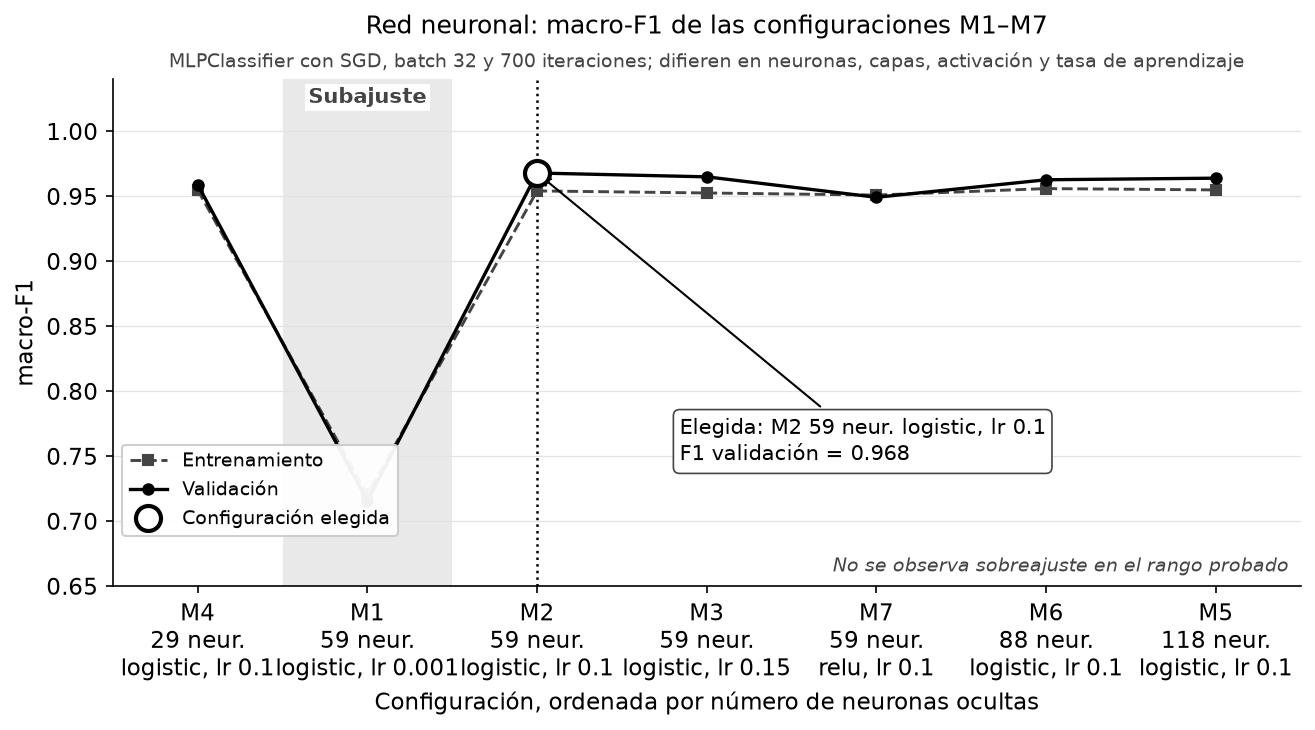

Guardada: resultados/red_neuronal/red_optimizacion_hiperparametros.png


In [6]:
comp = pd.read_csv(RES / "red_neuronal/comparacion_modelos_validacion.csv")
comp["config"] = comp["modelo"].str.split().str[0]
comp["capas"] = comp["neuronas"].apply(ast.literal_eval)
comp["n_neuronas"] = comp["capas"].apply(sum)
eleg_red = comp.sort_values("F1_v", ascending=False).iloc[0]   # mismo criterio que redes_neuronales.ipynb

### Tabla con las 7 configuraciones probadas
tabla_red = (comp.sort_values("config")
             .assign(brecha_F1=lambda t: t["F1_T"] - t["F1_v"],
                     elegida=lambda t: np.where(t["config"] == eleg_red["config"], "sí", ""))
             .rename(columns={"config": "configuracion", "modelo": "descripcion", "neuronas": "hidden_layer_sizes",
                              "n_neuronas": "neuronas_ocultas", "activacion": "activation",
                              "learning_rate": "learning_rate_init", "F1_T": "F1_entrenamiento",
                              "F1_v": "F1_validacion"})
             [["configuracion", "descripcion", "hidden_layer_sizes", "neuronas_ocultas", "activation",
               "learning_rate_init", "F1_entrenamiento", "F1_validacion", "brecha_F1", "elegida"]].round(4))
tabla_red.to_csv(RES / "red_neuronal/red_tabla_configuraciones.csv", index=False)
print("Guardada:", RES / "red_neuronal/red_tabla_configuraciones.csv")
display(tabla_red)

curva_red = comp.sort_values(["n_neuronas", "config"]).reset_index(drop=True)
i_eleg = int(np.flatnonzero(curva_red["config"] == eleg_red["config"])[0])
etiquetas_red = [f"{c}\n{n} neur.\n{a}, lr {lr:g}" for c, n, a, lr in
                 zip(curva_red["config"], curva_red["n_neuronas"], curva_red["activacion"], curva_red["learning_rate"])]
figura_hiperparametros(
    etiquetas_red, curva_red["F1_T"], curva_red["F1_v"], i_eleg,
    titulo="Red neuronal: macro-F1 de las configuraciones M1–M7",
    detalle="MLPClassifier con SGD, batch 32 y 700 iteraciones; difieren en neuronas, capas, activación y tasa de aprendizaje",
    xlabel="Configuración, ordenada por número de neuronas ocultas",
    ruta=RES / "red_neuronal/red_optimizacion_hiperparametros.png")

## 2. Matrices de confusión de árbol y bosque

Desde `matriz_confusion_prueba.csv` de cada carpeta, con el mismo estilo que las de KNN y la red.

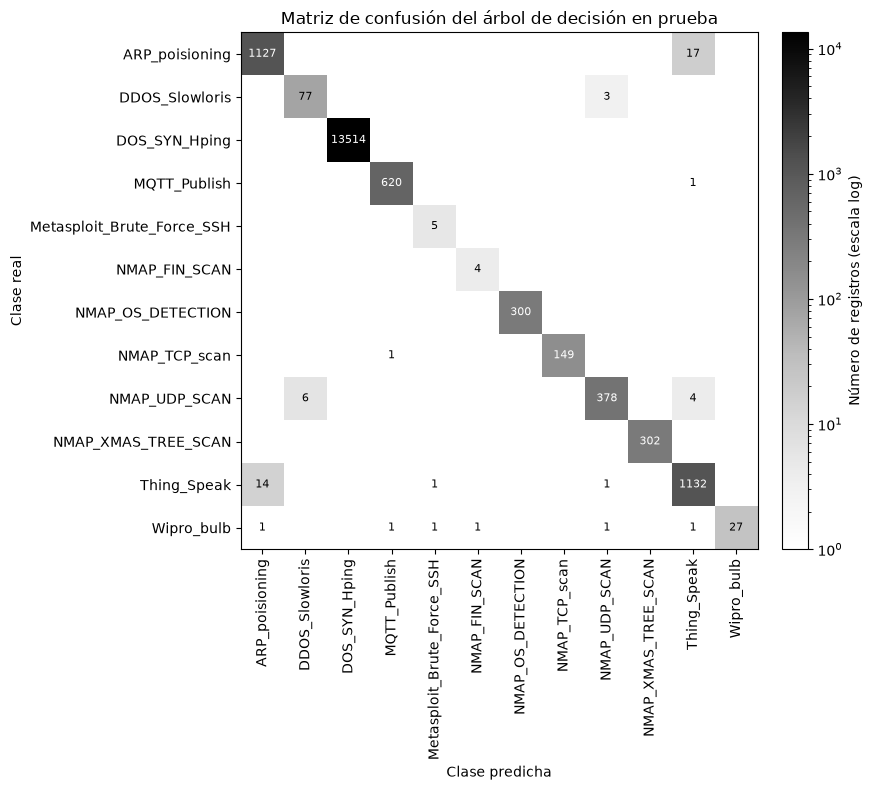

Guardada: resultados/arbol_decision/arbol_matriz_confusion.png


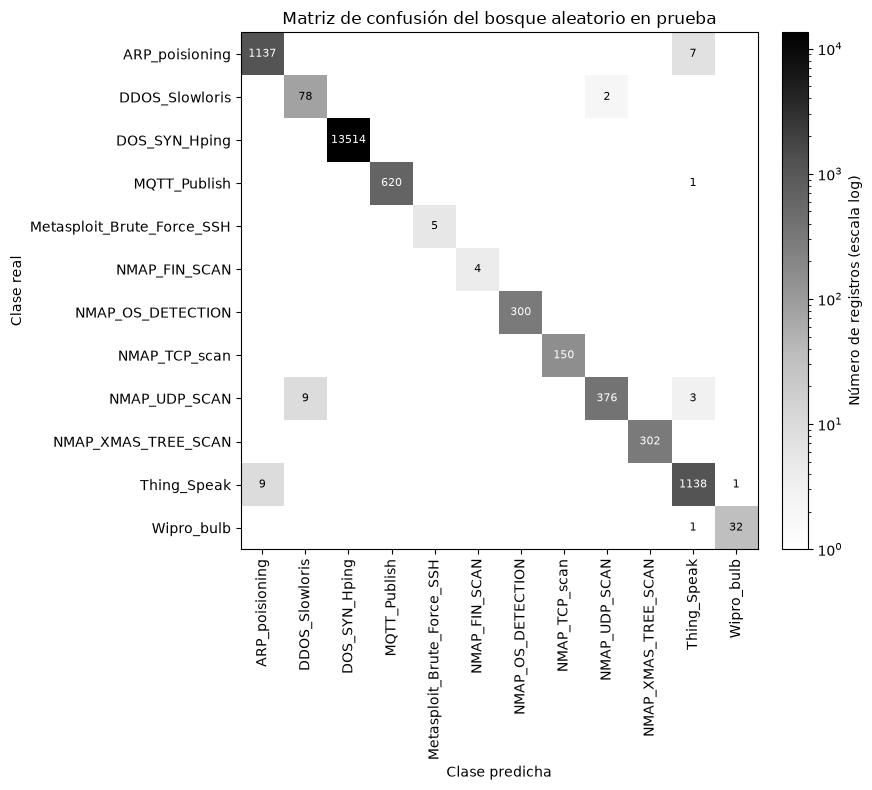

Guardada: resultados/bosque_aleatorio/bosque_matriz_confusion.png


In [7]:
for nombre, carpeta, prefijo, titulo in [
        ("Árbol de decisión", "arbol_decision", "arbol", "Matriz de confusión del árbol de decisión en prueba"),
        ("Bosque aleatorio", "bosque_aleatorio", "bosque", "Matriz de confusión del bosque aleatorio en prueba")]:
    cm_df = pd.read_csv(RES / carpeta / "matriz_confusion_prueba.csv", index_col=0)
    matriz_confusion(cm_df.values, list(cm_df.index), titulo, RES / carpeta / f"{prefijo}_matriz_confusion.png")

## 3. Comparación en prueba

Todas las métricas se calculan desde la matriz de confusión de prueba de cada modelo (las cuatro con las mismas 17 689 filas), y se contrastan con las que guardó cada notebook.

In [8]:
matrices = {nombre: pd.read_csv(RES / carpeta / "matriz_confusion_prueba.csv", index_col=0)
            for nombre, carpeta in MODELOS.items()}
clases = list(matrices["KNN"].index)
matrices = {m: cm.loc[clases, clases] for m, cm in matrices.items()}
assert len({int(cm.values.sum()) for cm in matrices.values()}) == 1, "Las matrices no tienen el mismo número de filas"


def metricas_por_clase(cm_df):
    cm = cm_df.values
    vp, reales, predichos = np.diag(cm), cm.sum(axis=1), cm.sum(axis=0)
    recall = vp / reales
    precision = np.divide(vp, predichos, out=np.zeros(len(vp)), where=predichos > 0)
    f1 = np.divide(2 * precision * recall, precision + recall, out=np.zeros(len(vp)), where=(precision + recall) > 0)
    return pd.DataFrame({"recall": recall, "precision": precision, "f1": f1, "soporte": reales}, index=cm_df.index)


por_clase = {m: metricas_por_clase(cm) for m, cm in matrices.items()}

filas = []
for m, cm in matrices.items():
    pc = por_clase[m]
    aciertos = int(np.trace(cm.values))
    filas.append({
        "modelo": m,
        "exactitud": aciertos / cm.values.sum(),
        "f1_macro": pc["f1"].mean(),
        "recall_macro": pc["recall"].mean(),
        "recall_SSH": pc.loc[SSH, "recall"], "precision_SSH": pc.loc[SSH, "precision"], "f1_SSH": pc.loc[SSH, "f1"],
        "recall_FIN": pc.loc[FIN, "recall"], "precision_FIN": pc.loc[FIN, "precision"], "f1_FIN": pc.loc[FIN, "f1"],
        "errores": int(cm.values.sum()) - aciertos,
    })
tabla_comp = pd.DataFrame(filas).set_index("modelo")
tabla_comp.round(4).to_csv(DIR_COMP / "tabla_comparativa_prueba.csv")
print("Guardada:", DIR_COMP / "tabla_comparativa_prueba.csv")

### Contraste con lo que guardó cada notebook
guardado = {
    "Árbol de decisión": pd.read_csv(RES / "arbol_decision/metricas_arbol_decision.csv", index_col=0).loc["prueba"],
    "Bosque aleatorio": pd.read_csv(RES / "bosque_aleatorio/metricas_bosque_aleatorio.csv", index_col=0).loc["prueba"],
    "KNN": pd.read_csv(RES / "knn/metricas_knn.csv", index_col=0).loc["prueba"],
}
for m, fila in guardado.items():
    for col in ["exactitud", "f1_macro", "recall_macro", "recall_SSH", "recall_FIN"]:
        assert np.isclose(tabla_comp.loc[m, col], fila[col]), (m, col)
vp_fn_fp = pd.read_csv(RES / "red_neuronal/vp_fn_fp_red_neuronal.csv", index_col=0).loc[clases]
assert (np.diag(matrices["Red neuronal"].values) == vp_fn_fp["VP"].values).all()
assert (matrices["Red neuronal"].values.sum(axis=0) - vp_fn_fp["VP"].values == vp_fn_fp["FP"].values).all()
print("Coinciden con las métricas guardadas por cada notebook.")

display(tabla_comp.round(3))

Guardada: resultados/comparacion/tabla_comparativa_prueba.csv
Coinciden con las métricas guardadas por cada notebook.


,exactitud,f1_macro,recall_macro,recall_SSH,precision_SSH,f1_SSH,recall_FIN,precision_FIN,f1_FIN,errores
modelo,,,,,,,,,,
Árbol de decisión,0.997,0.959,0.976,1.0,0.714,0.833,1.0,0.8,0.889,54
Bosque aleatorio,0.998,0.989,0.991,1.0,1.000,1.000,1.0,1.0,1.000,33
KNN,0.997,0.975,0.988,1.0,0.833,0.909,1.0,1.0,1.000,50
Red neuronal,0.996,0.979,0.981,1.0,1.000,1.000,1.0,1.0,1.000,66


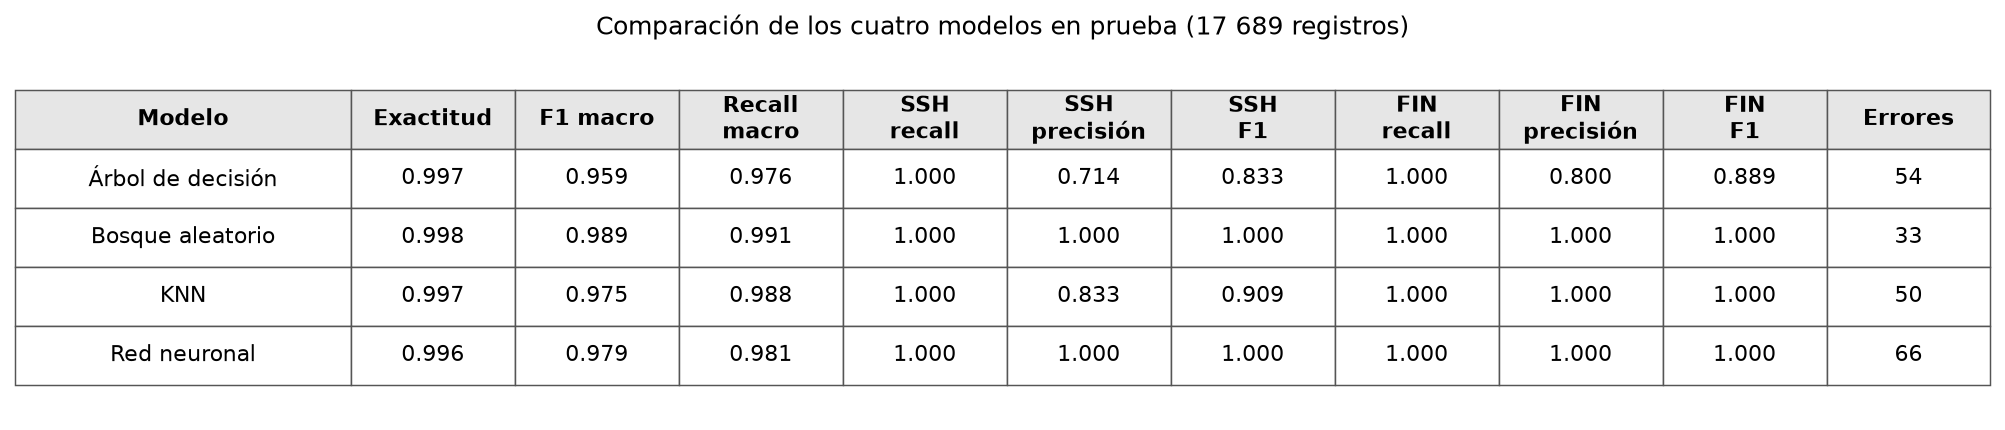

Guardada: resultados/comparacion/tabla_comparativa_prueba.png


In [9]:
### Figura de la tabla comparativa (mismo estilo que la tabla de fig2)
columnas = ["Exactitud", "F1 macro", "Recall\nmacro", "SSH\nrecall", "SSH\nprecisión", "SSH\nF1",
            "FIN\nrecall", "FIN\nprecisión", "FIN\nF1", "Errores"]
celdas = [[m] + [f"{v:.3f}" for v in fila.drop("errores")] + [f"{int(fila['errores'])}"]
          for m, fila in tabla_comp.iterrows()]

fig, ax = plt.subplots(figsize=(13.5, 3.0))
ax.axis("off")
ax.set_title("Comparación de los cuatro modelos en prueba (17 689 registros)", pad=12)
tabla = ax.table(cellText=celdas, colLabels=["Modelo"] + columnas, loc="center", cellLoc="center",
                 colWidths=[0.17] + [0.083] * len(columnas))
tabla.auto_set_font_size(False)
tabla.set_fontsize(10.5)
tabla.scale(1.0, 2.3)
for (r, c), celda in tabla.get_celld().items():
    celda.set_edgecolor("#555555")
    celda.set_linewidth(0.7)
    if r == 0:
        celda.set_facecolor("#e6e6e6")
        celda.get_text().set_fontweight("bold")
    else:
        celda.set_facecolor("white")

plt.tight_layout()
ruta = DIR_COMP / "tabla_comparativa_prueba.png"
plt.savefig(ruta, dpi=300)
plt.show()
print("Guardada:", ruta)

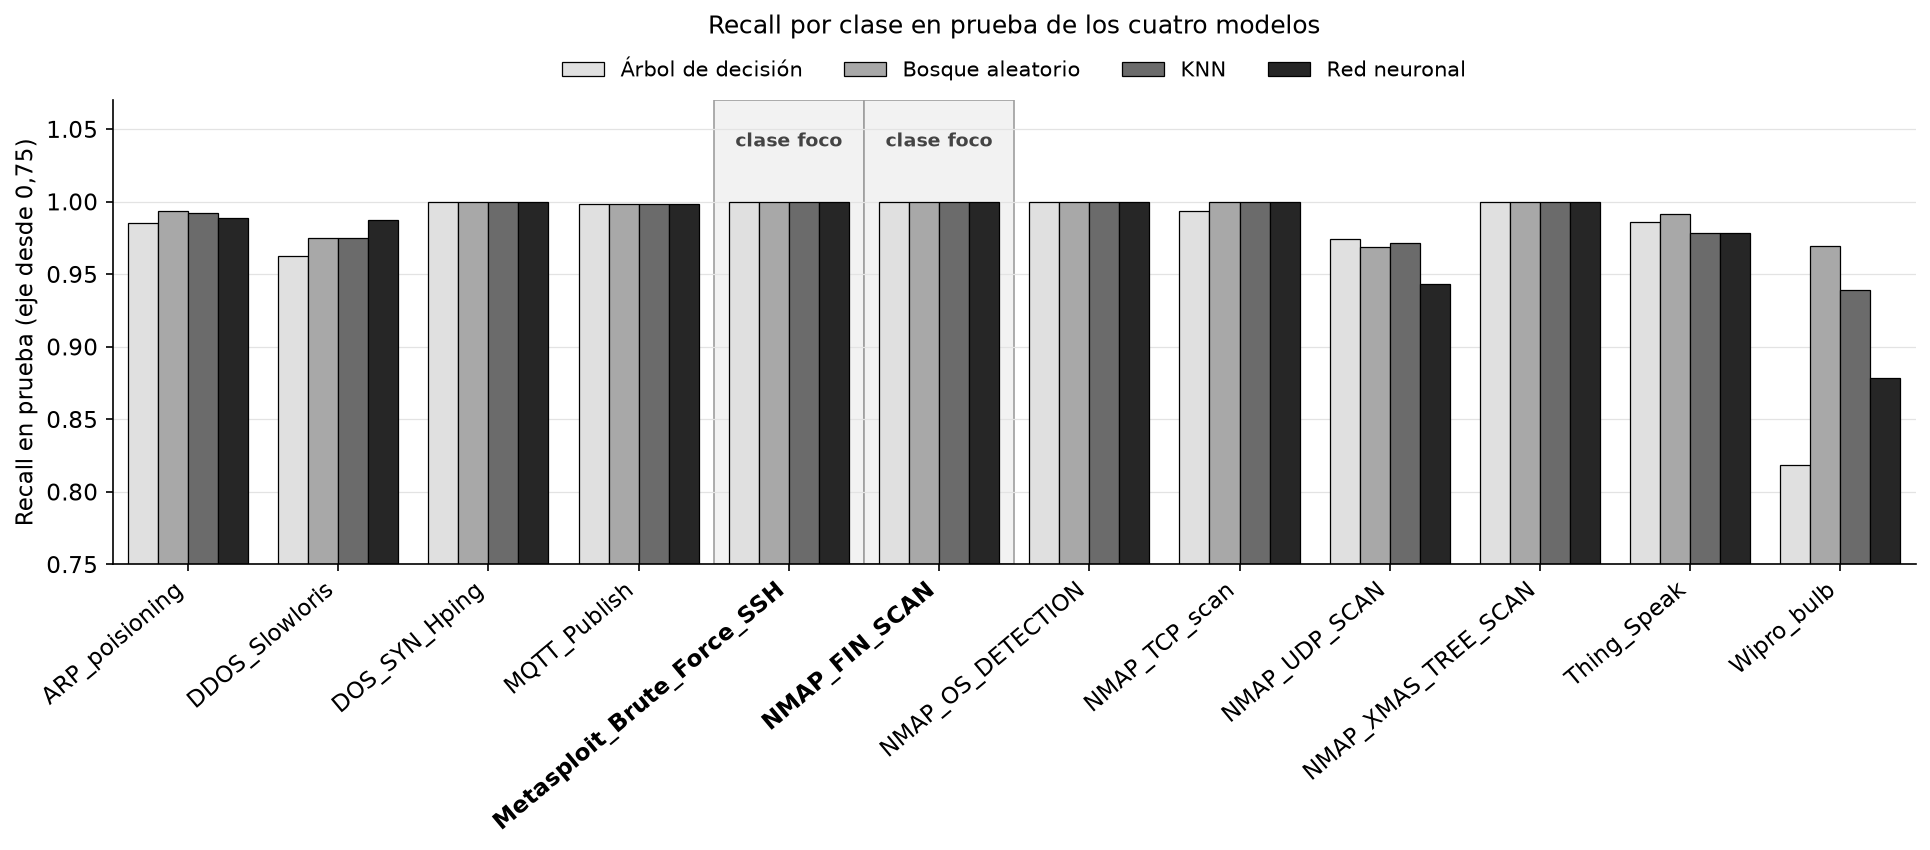

Guardada: resultados/comparacion/recall_por_clase_4_modelos.png


,Árbol de decisión,Bosque aleatorio,KNN,Red neuronal
ARP_poisioning,0.985,0.994,0.992,0.989
DDOS_Slowloris,0.962,0.975,0.975,0.988
DOS_SYN_Hping,1.000,1.000,1.000,1.000
MQTT_Publish,0.998,0.998,0.998,0.998
Metasploit_Brute_Force_SSH,1.000,1.000,1.000,1.000
NMAP_FIN_SCAN,1.000,1.000,1.000,1.000
NMAP_OS_DETECTION,1.000,1.000,1.000,1.000
NMAP_TCP_scan,0.993,1.000,1.000,1.000
NMAP_UDP_SCAN,0.974,0.969,0.972,0.943
NMAP_XMAS_TREE_SCAN,1.000,1.000,1.000,1.000


In [10]:
### Recall por clase: 12 clases x 4 modelos
recall = pd.DataFrame({m: pc["recall"] for m, pc in por_clase.items()})
recall.round(4).rename_axis("clase").to_csv(DIR_COMP / "recall_por_clase_4_modelos.csv")

grises = ["#e0e0e0", "#a8a8a8", "#6b6b6b", "#262626"]
x = np.arange(len(clases))
ancho = 0.2
ymin = 0.75

fig, ax = plt.subplots(figsize=(13, 5.8))
for k in [clases.index(SSH), clases.index(FIN)]:
    ax.axvspan(k - 0.5, k + 0.5, facecolor="#f2f2f2", edgecolor="#9e9e9e", linewidth=0.8, zorder=0)
    ax.text(k, 1.035, "clase foco", ha="center", va="bottom", fontsize=9, color=GRAY, fontweight="bold")
for i, (m, color) in enumerate(zip(recall.columns, grises)):
    ax.bar(x + (i - 1.5) * ancho, recall[m], width=ancho, color=color, edgecolor=BLACK, linewidth=0.6, label=m, zorder=2)

ax.set_xticks(x, clases, rotation=40, ha="right")
for etiqueta in ax.get_xticklabels():
    if etiqueta.get_text() in (SSH, FIN):
        etiqueta.set_fontweight("bold")
ax.set_ylim(ymin, 1.07)
ax.set_xlim(-0.5, len(clases) - 0.5)
ax.set_ylabel(f"Recall en prueba (eje desde {ymin:.2f})".replace(".", ","))
ax.set_title("Recall por clase en prueba de los cuatro modelos", pad=32)
ax.grid(axis="y", color="#e3e3e3", linewidth=0.6, zorder=1)
ax.legend(ncol=4, loc="lower center", bbox_to_anchor=(0.5, 1.0), frameon=False, fontsize=10)

plt.tight_layout()
ruta = DIR_COMP / "recall_por_clase_4_modelos.png"
plt.savefig(ruta, dpi=300)
plt.show()
print("Guardada:", ruta)
display(recall.round(3))

## 4. Distribución de clases

Desde `resultados/datos/distribucion_clases.csv`, que guarda `preparacion_datos.ipynb` (conteo tras quitar los duplicados exactos).

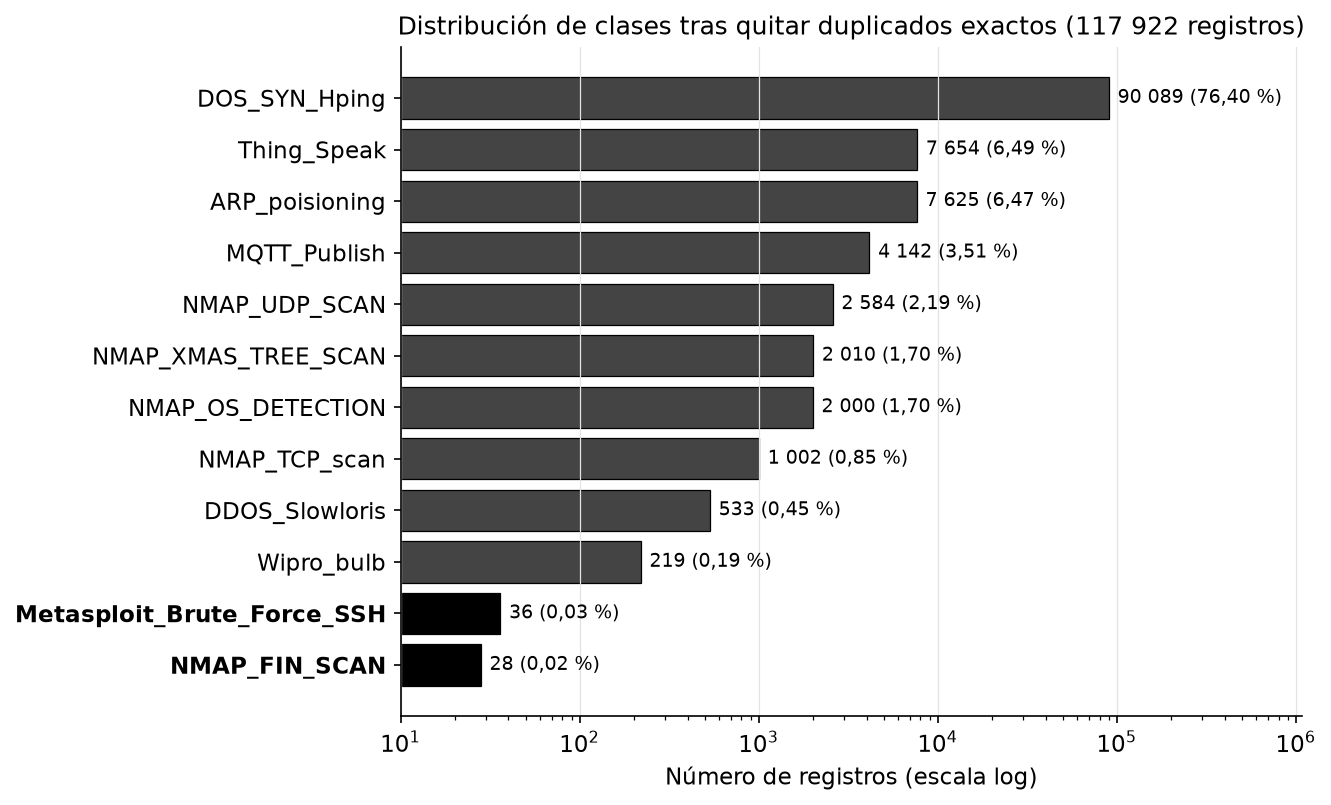

Guardada: resultados/comparacion/distribucion_clases.png


In [11]:
dist = pd.read_csv(RES / "datos/distribucion_clases.csv", index_col=0)["final"].sort_values()
colores = [BLACK if c in (SSH, FIN) else GRAY for c in dist.index]

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(dist.index, dist.values, color=colores, edgecolor=BLACK, linewidth=0.6)
ax.set_xscale("log")
for i, v in enumerate(dist.values):
    ax.text(v * 1.12, i, f"{v:,}".replace(",", " ") + f" ({v / dist.sum() * 100:.2f} %)".replace(".", ","),
            va="center", fontsize=9)
for etiqueta in ax.get_yticklabels():
    if etiqueta.get_text() in (SSH, FIN):
        etiqueta.set_fontweight("bold")
ax.set_xlim(10, dist.max() * 12)
ax.set_xlabel("Número de registros (escala log)")
ax.set_title(f"Distribución de clases tras quitar duplicados exactos ({dist.sum():,} registros)".replace(",", " "))
ax.grid(axis="x", color="#e3e3e3", linewidth=0.6)

plt.tight_layout()
ruta = DIR_COMP / "distribucion_clases.png"
plt.savefig(ruta, dpi=300)
plt.show()
print("Guardada:", ruta)

## 5. Figuras adicionales

No se reentrena nada: todo sale de los CSV de `resultados/` ya leídos arriba (`matrices`, `tabla_comp`, `curva_red`).

1. Matrices de confusión en prueba recortadas a SSH, FIN, ARP_poisioning, Thing_Speak y Wipro_bulb, con la misma escala en los cuatro modelos.
2. Figura de la red con el eje X solo como M1–M7 (el detalle de cada configuración está en `red_tabla_configuraciones.csv`).
3. Falsos positivos de SSH y FIN en la tabla comparativa.

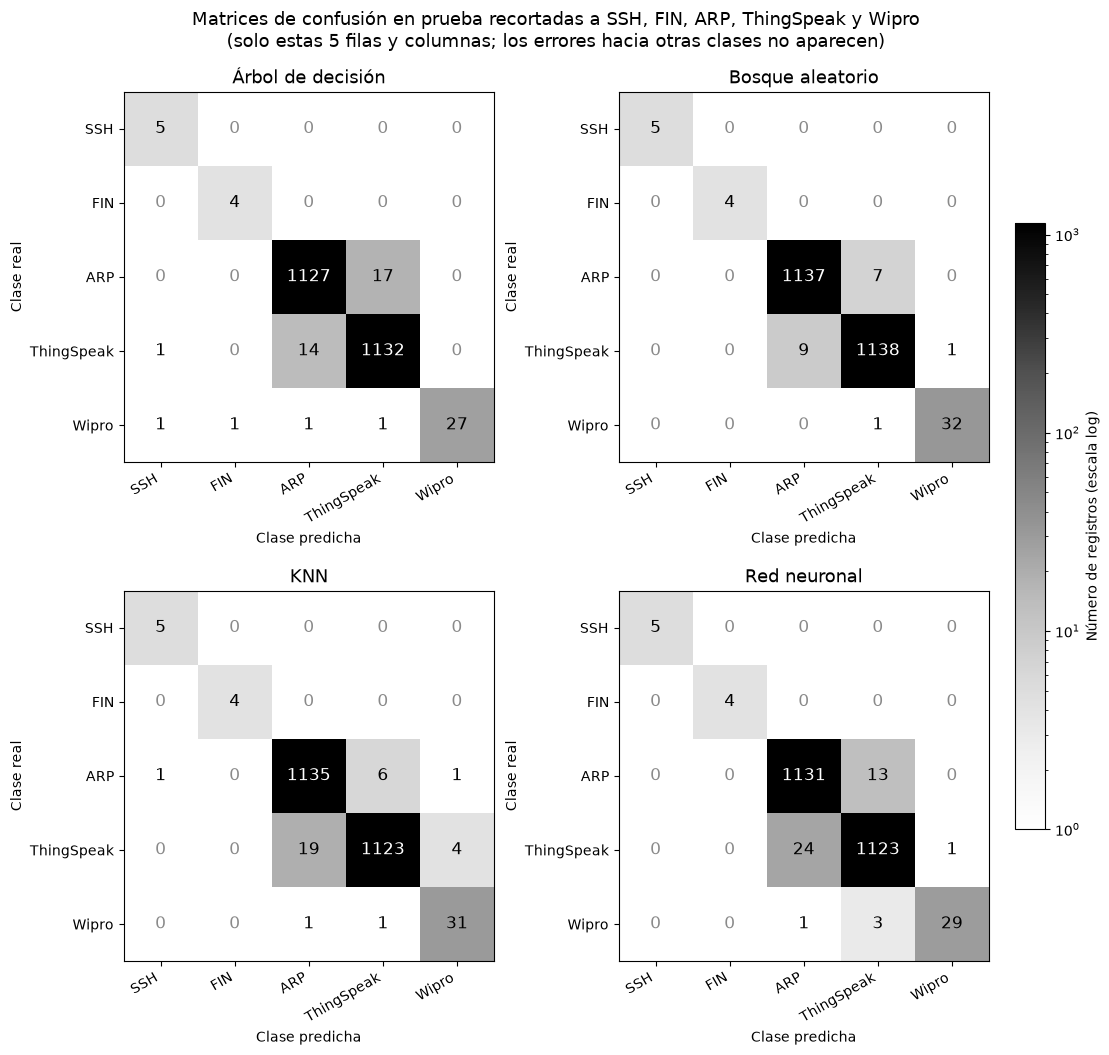

Guardada: resultados/comparacion/matrices_recortadas_4_modelos.png


In [12]:
### Matrices de confusión recortadas (mismas filas, columnas y escala en los 4 paneles)
clases_rec = [SSH, FIN, "ARP_poisioning", "Thing_Speak", "Wipro_bulb"]
abrev = {SSH: "SSH", FIN: "FIN", "ARP_poisioning": "ARP", "Thing_Speak": "ThingSpeak", "Wipro_bulb": "Wipro"}
etiquetas_rec = [abrev[c] for c in clases_rec]

recortes = {m: cm.loc[clases_rec, clases_rec].values for m, cm in matrices.items()}
norma = LogNorm(vmin=1, vmax=max(r.max() for r in recortes.values()))

with plt.style.context("default"):
    cmap = plt.get_cmap("Greys").copy()
    cmap.set_bad("white")

    fig, axes = plt.subplots(2, 2, figsize=(11, 10.5), constrained_layout=True)
    for ax, (m, r) in zip(axes.flat, recortes.items()):
        im = ax.imshow(np.ma.masked_equal(r, 0), cmap=cmap, norm=norma)
        for i in range(r.shape[0]):
            for j in range(r.shape[1]):
                if r[i, j] == 0:
                    color = "#8a8a8a"
                else:
                    color = "white" if norma(r[i, j]) > 0.5 else "black"
                ax.text(j, i, r[i, j], ha="center", va="center", fontsize=12, color=color)
        ax.set_xticks(range(len(etiquetas_rec)), etiquetas_rec, rotation=30, ha="right")
        ax.set_yticks(range(len(etiquetas_rec)), etiquetas_rec)
        ax.set_xlabel("Clase predicha")
        ax.set_ylabel("Clase real")
        ax.set_title(m, fontsize=13)

    fig.colorbar(im, ax=axes, fraction=0.035, pad=0.03, label="Número de registros (escala log)")
    fig.suptitle("Matrices de confusión en prueba recortadas a SSH, FIN, ARP, ThingSpeak y Wipro\n"
                 "(solo estas 5 filas y columnas; los errores hacia otras clases no aparecen)", fontsize=13)
    ruta = DIR_COMP / "matrices_recortadas_4_modelos.png"
    plt.savefig(ruta, dpi=300)
    plt.show()
print("Guardada:", ruta)


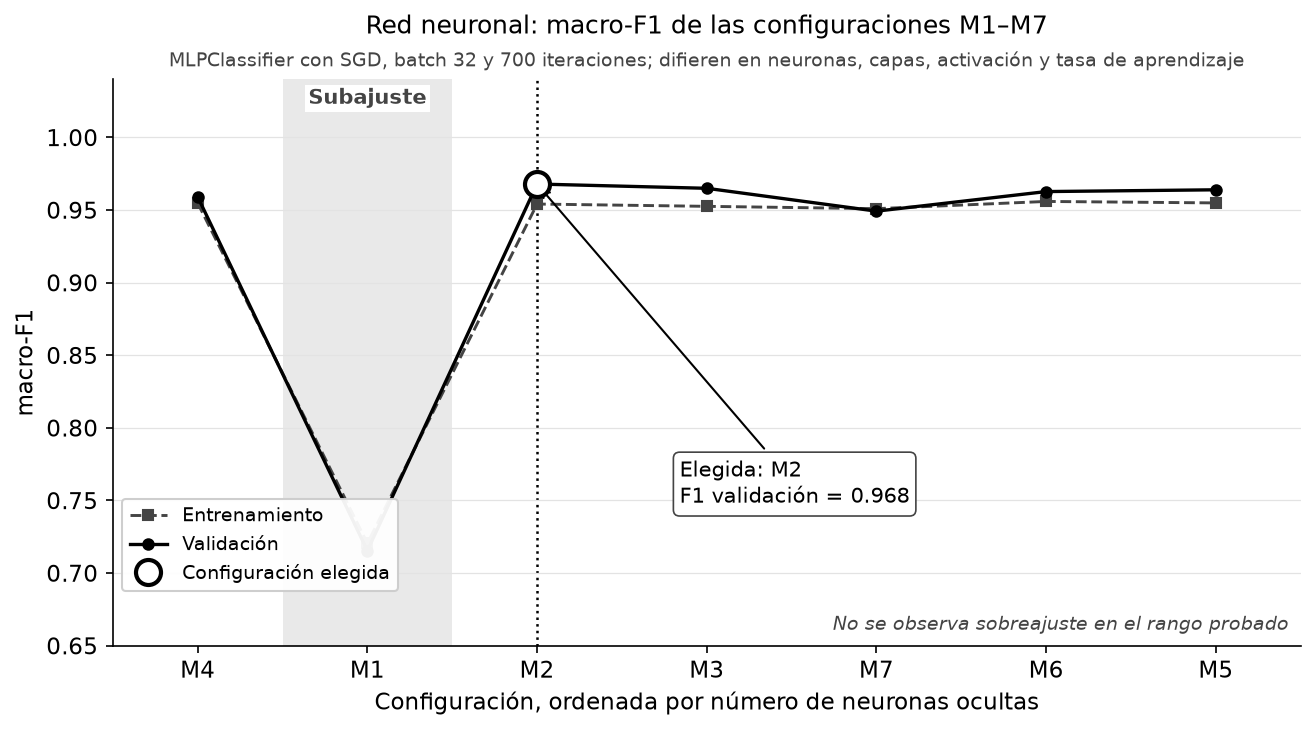

Guardada: resultados/red_neuronal/red_optimizacion_hiperparametros.png


In [13]:
### Red neuronal: misma figura, con el eje X solo M1..M7 (mismo orden por neuronas ocultas)
i_eleg = int(np.flatnonzero(curva_red["config"] == eleg_red["config"])[0])
figura_hiperparametros(
    list(curva_red["config"]), curva_red["F1_T"], curva_red["F1_v"], i_eleg,
    titulo="Red neuronal: macro-F1 de las configuraciones M1–M7",
    detalle="MLPClassifier con SGD, batch 32 y 700 iteraciones; difieren en neuronas, capas, activación y tasa de aprendizaje",
    xlabel="Configuración, ordenada por número de neuronas ocultas",
    ruta=RES / "red_neuronal/red_optimizacion_hiperparametros.png")


Guardada: resultados/comparacion/tabla_comparativa_prueba.csv


,exactitud,f1_macro,recall_macro,recall_SSH,precision_SSH,f1_SSH,FP SSH,recall_FIN,precision_FIN,f1_FIN,FP FIN,errores
modelo,,,,,,,,,,,,
Árbol de decisión,0.997,0.959,0.976,1.0,0.714,0.833,2,1.0,0.8,0.889,1,54
Bosque aleatorio,0.998,0.989,0.991,1.0,1.000,1.000,0,1.0,1.0,1.000,0,33
KNN,0.997,0.975,0.988,1.0,0.833,0.909,1,1.0,1.0,1.000,0,50
Red neuronal,0.996,0.979,0.981,1.0,1.000,1.000,0,1.0,1.0,1.000,0,66


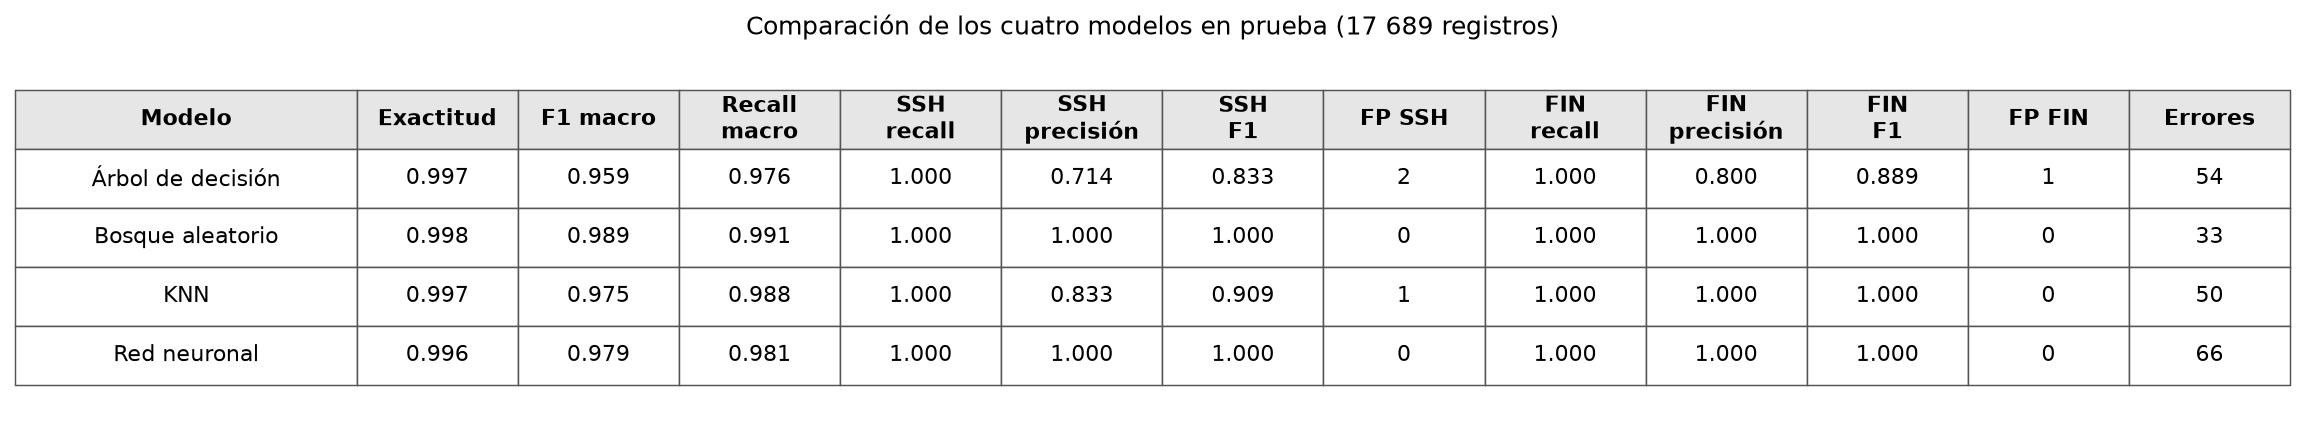

Guardada: resultados/comparacion/tabla_comparativa_prueba.png


In [14]:
### FP de SSH y FIN: registros de otras clases que el modelo predijo como SSH o FIN
for clase in (SSH, FIN):
    vp = pd.Series({m: int(cm.loc[clase, clase]) for m, cm in matrices.items()})
    fp = pd.Series({m: int(cm[clase].sum()) for m, cm in matrices.items()}) - vp
    assert np.allclose(vp / (vp + fp), tabla_comp[f"precision_{abrev[clase]}"]), clase
    tabla_comp[f"FP {abrev[clase]}"] = fp

tabla_comp = tabla_comp[["exactitud", "f1_macro", "recall_macro",
                         "recall_SSH", "precision_SSH", "f1_SSH", "FP SSH",
                         "recall_FIN", "precision_FIN", "f1_FIN", "FP FIN", "errores"]]
tabla_comp.round(4).to_csv(DIR_COMP / "tabla_comparativa_prueba.csv")
print("Guardada:", DIR_COMP / "tabla_comparativa_prueba.csv")
display(tabla_comp.round(3))

### Figura de la tabla (mismo estilo que arriba, con las dos columnas nuevas)
enteras = ["FP SSH", "FP FIN", "errores"]
columnas = ["Exactitud", "F1 macro", "Recall\nmacro", "SSH\nrecall", "SSH\nprecisión", "SSH\nF1", "FP SSH",
            "FIN\nrecall", "FIN\nprecisión", "FIN\nF1", "FP FIN", "Errores"]
celdas = [[m] + [f"{int(v)}" if c in enteras else f"{v:.3f}" for c, v in fila.items()]
          for m, fila in tabla_comp.iterrows()]

fig, ax = plt.subplots(figsize=(15.5, 3.0))
ax.axis("off")
ax.set_title("Comparación de los cuatro modelos en prueba (17 689 registros)", pad=12)
tabla = ax.table(cellText=celdas, colLabels=["Modelo"] + columnas, loc="center", cellLoc="center",
                 colWidths=[0.15] + [0.0708] * len(columnas))
tabla.auto_set_font_size(False)
tabla.set_fontsize(10.5)
tabla.scale(1.0, 2.3)
for (r, c), celda in tabla.get_celld().items():
    celda.set_edgecolor("#555555")
    celda.set_linewidth(0.7)
    if r == 0:
        celda.set_facecolor("#e6e6e6")
        celda.get_text().set_fontweight("bold")
    else:
        celda.set_facecolor("white")

plt.tight_layout()
ruta = DIR_COMP / "tabla_comparativa_prueba.png"
plt.savefig(ruta, dpi=300)
plt.show()
print("Guardada:", ruta)
